# Notebook 3: Exploratory Data Analysis

# Hotel Revenue Management & Dynamic Pricing Intelligence

---

## Project Workflow

- Notebook 1 — Business Understanding & Data Audit
- Notebook 2 — Data Cleaning & Feature Engineering
- ✅ Notebook 3 — Exploratory Data Analysis *(Current Notebook)*
- Notebook 4 — SQL Business Analytics
- Notebook 5 — Revenue Management Simulation

---

## 1. Objective

The objective of this notebook is to explore booking behaviour, customer demand, pricing patterns, cancellations, and seasonal trends to identify the key drivers influencing hotel revenue.

The insights generated in this notebook will guide the SQL analysis, executive dashboards, and the rule-based dynamic pricing engine developed in later stages of the project.

In [1]:
# ==========================================================
# 1. Import Libraries
# ==========================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load & Understand the Dataset

The cleaned dataset produced in Notebook 2 is loaded and verified before beginning the exploratory analysis.

Basic validation is performed to confirm the dataset dimensions and ensure that all engineered features are available for analysis.

In [2]:
# ==========================================================
# 2. Load Clean Dataset
# ==========================================================

df = pd.read_csv(
    "../data/processed/hotel_bookings_cleaned.csv",
    parse_dates=[
        "arrival_date",
        "departure_date",
        "reservation_status_date"
    ]
)

print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

df.head()

Rows    : 119,390
Columns : 49


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date,stay_duration,departure_date,total_guests,booking_source,lead_time_bucket,arrival_season,weekend_arrival,arrival_month_number,arrival_day_name,guest_nights,weekend_stay,room_nights,booking_status,arrival_quarter,arrival_year_month,family_type
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01,0,2015-07-01,2,Direct,90+ Days,Summer,Weekday,7,Wednesday,0,No,0,Completed,Q3,2015-07,Couple
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01,0,2015-07-01,2,Direct,90+ Days,Summer,Weekday,7,Wednesday,0,No,0,Completed,Q3,2015-07,Couple
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01,1,2015-07-02,1,Direct,0-7 Days,Summer,Weekday,7,Wednesday,1,No,1,Completed,Q3,2015-07,Solo
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01,1,2015-07-02,1,Travel Agent,8-30 Days,Summer,Weekday,7,Wednesday,1,No,1,Completed,Q3,2015-07,Solo
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,2015-07-01,2,2015-07-03,2,Travel Agent,8-30 Days,Summer,Weekday,7,Wednesday,4,No,2,Completed,Q3,2015-07,Couple


## 3. Dataset Overview

Before exploring business questions, the overall structure of the analytical dataset is reviewed.

This includes the dataset dimensions, feature composition, and data types to establish a clear understanding of the information available for analysis.

In [3]:
# ==========================================================
# Dataset Snapshot
# ==========================================================

summary = pd.DataFrame({
    "Metric":[
        "Rows",
        "Columns",
        "Numerical Features",
        "Categorical Features"
    ],
    "Value":[
        df.shape[0],
        df.shape[1],
        len(df.select_dtypes(include="number").columns),
        len(df.select_dtypes(include=["object","category"]).columns)
    ]
})

summary

,Metric,Value
0,Rows,119390
1,Columns,49
2,Numerical Features,25
3,Categorical Features,21


## 4. Customer Demand Analysis

Understanding customer demand is the first step in designing an effective revenue management strategy.

This section examines booking volume across hotel types, seasons, customer segments, and booking channels to identify the primary sources of demand.

### Business Question 1

**Which hotel type receives the highest booking demand?**

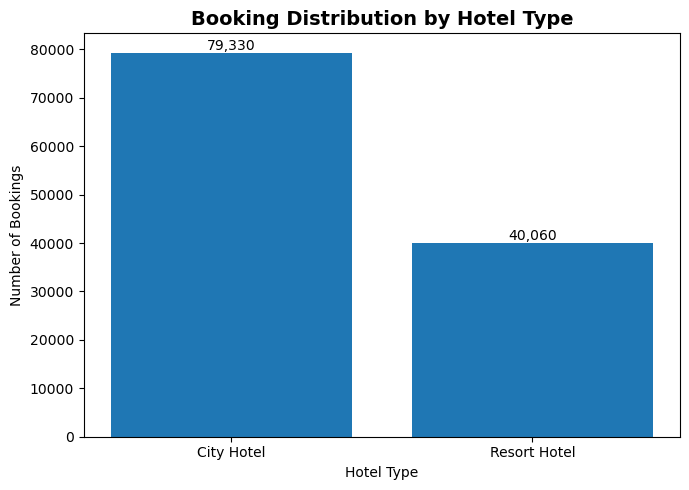

In [4]:
# ==========================================================
# Booking Distribution by Hotel Type
# ==========================================================

hotel_counts = (
    df["hotel"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    hotel_counts.index,
    hotel_counts.values
)

plt.title("Booking Distribution by Hotel Type", fontsize=14, fontweight="bold")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")

# Add value labels
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### Observations

- City Hotels account for **79,330 reservations**, representing nearly twice the booking volume of Resort Hotels.
- Resort Hotels received **40,060 reservations**, indicating substantially lower overall demand.
- The booking distribution suggests that the majority of customers prefer city accommodations over resort properties.

### Business Insight

City Hotels represent the primary revenue driver due to their significantly higher booking volume. Revenue optimization strategies such as dynamic pricing, occupancy forecasting, and demand monitoring should prioritize City Hotels, while Resort Hotels may require targeted promotional campaigns to stimulate demand during off-peak periods.

### Business Question 2

**How does booking demand change throughout the year?**

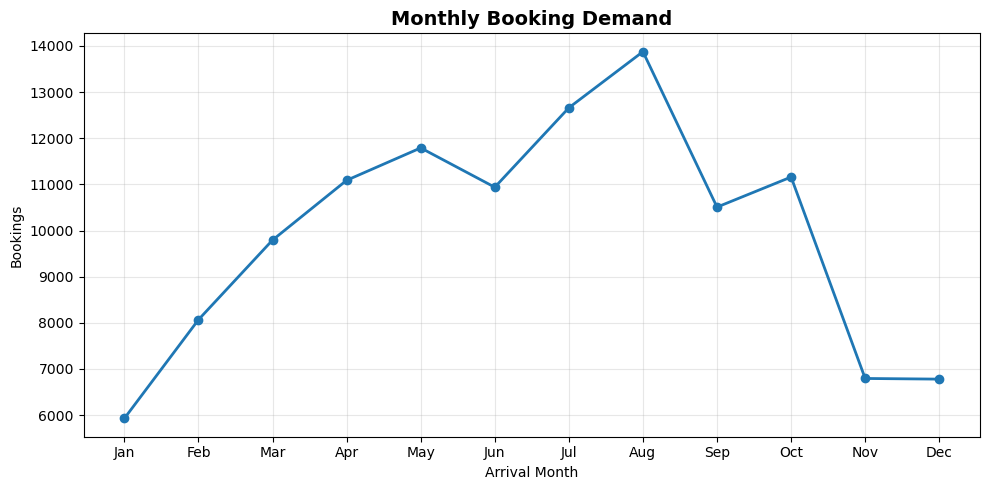

In [5]:
# ==========================================================
# Monthly Booking Demand
# ==========================================================

monthly_bookings = (
    df.groupby("arrival_month_number")
      .size()
)

month_labels = [
    "Jan","Feb","Mar","Apr","May","Jun",
    "Jul","Aug","Sep","Oct","Nov","Dec"
]

plt.figure(figsize=(10,5))

plt.plot(
    monthly_bookings.index,
    monthly_bookings.values,
    linewidth=2,
    marker="o"
)

plt.xticks(range(1,13), month_labels)

plt.title("Monthly Booking Demand", fontsize=14, fontweight="bold")
plt.xlabel("Arrival Month")
plt.ylabel("Bookings")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

### Observations

- Booking demand steadily increases from **January through August**, reaching its highest level during **August**.
- Demand declines noticeably after August, with a gradual decrease through September and October.
- **November and December** record the lowest booking volumes, indicating a clear off-season.
- The overall pattern demonstrates strong seasonality in hotel reservations.

### Business Insight

Booking demand is highly seasonal, with peak demand concentrated during the summer months. Dynamic pricing strategies should capitalize on high-demand periods by increasing room rates during July and August, while promotional pricing and marketing campaigns should be considered during the low-demand months to improve occupancy.

### Business Question 3

**Which booking sources generate the highest demand?**

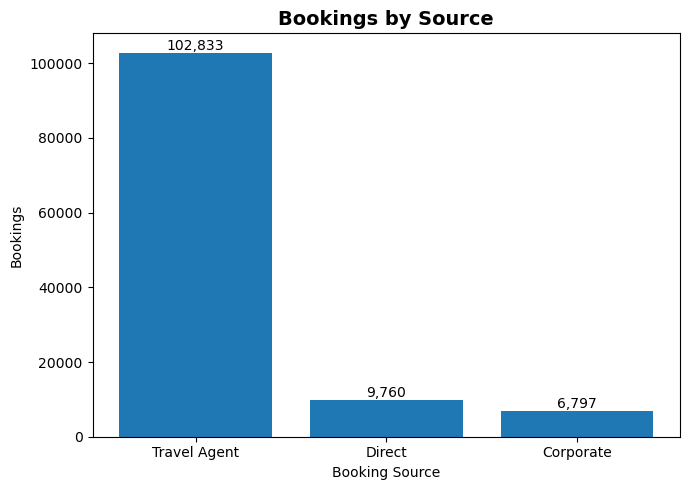

In [6]:
booking_source = (
    df["booking_source"]
    .value_counts()
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    booking_source.index,
    booking_source.values
)

plt.title("Bookings by Source", fontsize=14, fontweight="bold")
plt.xlabel("Booking Source")
plt.ylabel("Bookings")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- **Travel Agents** generated **102,833 reservations**, accounting for the vast majority of bookings.
- Direct bookings contributed **9,760 reservations**, representing a relatively small share.
- Corporate bookings were the lowest at **6,797 reservations**.
- The hotel network is heavily dependent on third-party booking channels.

### Business Insight

Travel Agents are the dominant acquisition channel and play a critical role in driving occupancy. While these partnerships are valuable, increasing direct bookings through loyalty programs, targeted marketing, and website promotions could reduce commission costs and improve overall profitability.

### Business Question 4

**Which customer groups generate the most bookings?**

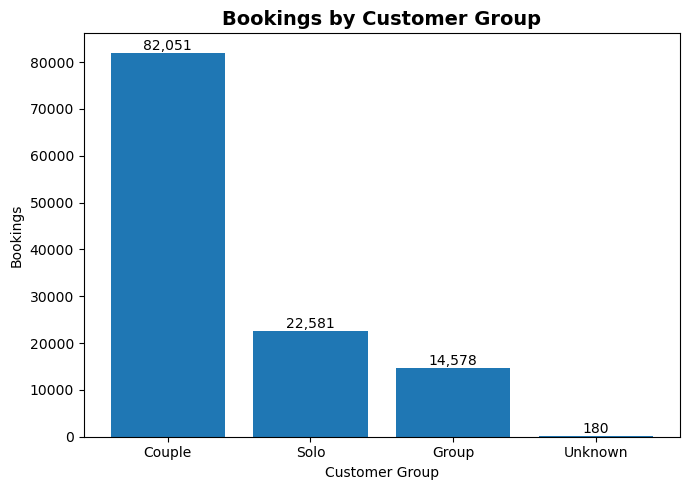

In [7]:
family = (
    df["family_type"]
    .value_counts()
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    family.index,
    family.values
)

plt.title("Bookings by Customer Group", fontsize=14, fontweight="bold")
plt.xlabel("Customer Group")
plt.ylabel("Bookings")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- **Couples** represent the largest customer segment with **82,051 reservations**.
- Solo travellers account for **22,581 bookings**, making them the second-largest segment.
- Group bookings total **14,578 reservations**, while only **180 bookings** fall into the Unknown category.
- Leisure travellers travelling as couples appear to be the hotel's primary customer base.

### Business Insight

Couples constitute the hotel's most valuable customer segment and should be the primary focus of pricing strategies, promotional packages, and marketing campaigns. Tailored weekend packages, romantic getaway offers, and seasonal promotions may further strengthen demand from this customer group, while targeted offers for solo and group travellers can help diversify revenue sources.

### Section Summary

Customer demand is primarily concentrated in **City Hotels**, with booking activity peaking during the summer months. The analysis also reveals a strong reliance on **Travel Agent** bookings and identifies **Couples** as the dominant customer segment.

These findings establish the demand baseline for the project and highlight the key customer and market characteristics that will influence occupancy planning, pricing decisions, and revenue optimization in the subsequent analyses.

## 5. Booking Behaviour Analysis

Understanding how customers make reservations provides valuable insight into booking patterns, demand predictability, and operational planning.

This section examines booking lead times, reservation durations, customer loyalty, and booking modifications to identify behavioural trends that influence occupancy and revenue management decisions.

### Business Question 1

**How far in advance do customers typically book their stay?**

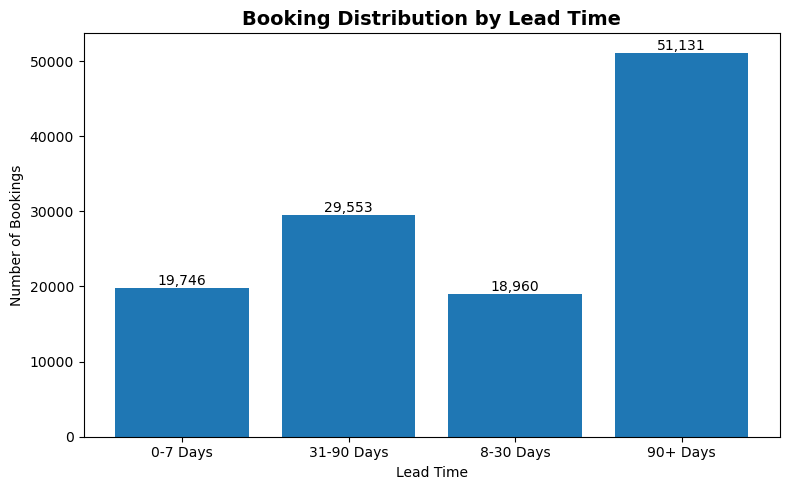

In [8]:
# ==========================================================
# Booking Distribution by Lead Time
# ==========================================================

lead_time = (
    df["lead_time_bucket"]
      .value_counts()
      .sort_index()
)

plt.figure(figsize=(8,5))

bars = plt.bar(
    lead_time.index.astype(str),
    lead_time.values
)

plt.title(
    "Booking Distribution by Lead Time",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Lead Time")
plt.ylabel("Number of Bookings")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### Observations

- The largest proportion of reservations (**51,131 bookings**) were made more than **90 days before arrival**.
- Medium-term bookings (**31–90 days**) represent the second-largest booking window.
- Short-term reservations (0–30 days) account for a considerably smaller share of total bookings.
- Overall, customers tend to plan their hotel stays well in advance rather than making last-minute reservations.

### Business Insight

Most customers reserve their accommodation several months before arrival, providing hotels with early visibility into future demand. This allows revenue managers to implement gradual price adjustments as occupancy increases instead of relying solely on last-minute pricing decisions.

### Business Question 2

**What is the typical length of stay for hotel reservations?**

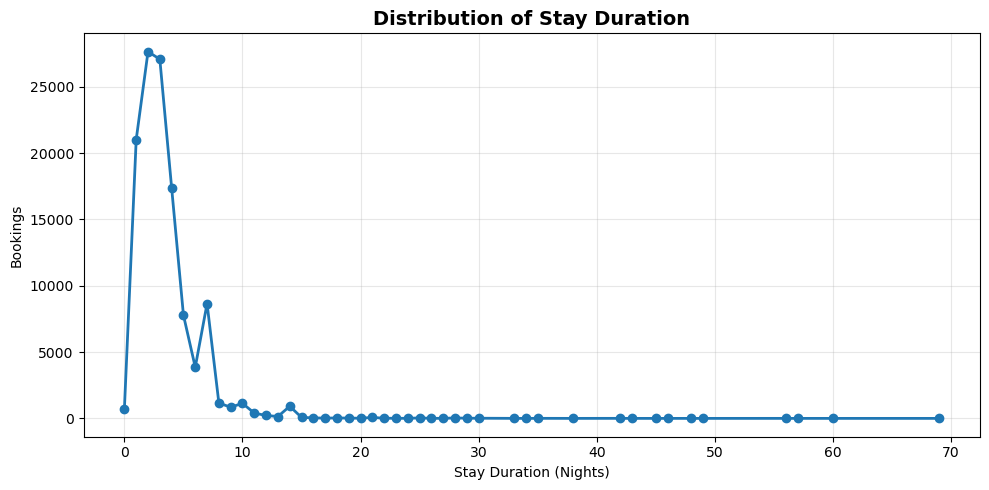

In [9]:
# ==========================================================
# Stay Duration Distribution
# ==========================================================

stay = (
    df["stay_duration"]
      .value_counts()
      .sort_index()
)

plt.figure(figsize=(10,5))

plt.plot(
    stay.index,
    stay.values,
    marker="o",
    linewidth=2
)

plt.title(
    "Distribution of Stay Duration",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Stay Duration (Nights)")
plt.ylabel("Bookings")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observations

- The majority of reservations are concentrated within short stays of approximately **2–5 nights**.
- Booking frequency declines rapidly as the length of stay increases.
- Long-duration stays are relatively uncommon and represent only a small proportion of total reservations.
- The distribution is strongly right-skewed, with a few extended stays creating a long tail.

### Business Insight

The hotel primarily serves short-stay travellers, indicating that pricing, housekeeping schedules, and room turnover strategies should be optimized for frequent guest arrivals and departures. Long-term stays represent a niche segment that may benefit from dedicated extended-stay packages or discounted weekly rates.

### Business Question 3

**What proportion of reservations come from repeat guests?**

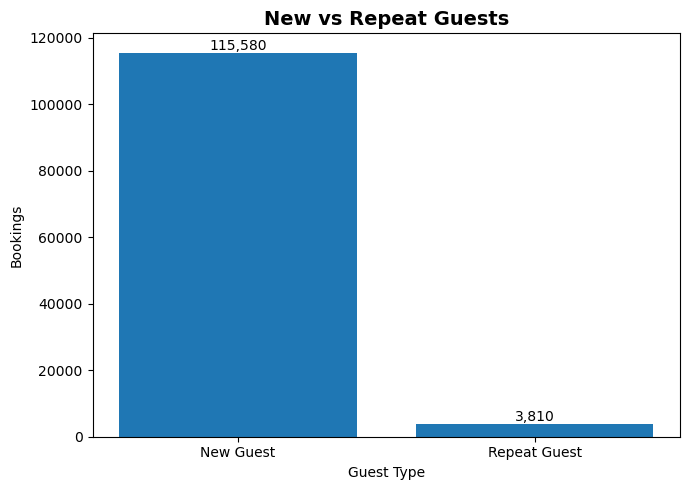

In [10]:
# ==========================================================
# Repeat Guest Analysis
# ==========================================================

repeat = (
    df["is_repeated_guest"]
      .replace({
          0: "New Guest",
          1: "Repeat Guest"
      })
      .value_counts()
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    repeat.index,
    repeat.values
)

plt.title(
    "New vs Repeat Guests",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Guest Type")
plt.ylabel("Bookings")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- New guests account for **115,580 reservations**, representing the overwhelming majority of bookings.
- Only **3,810 reservations** were made by repeat guests.
- Returning customers constitute a very small share of the overall customer base.

### Business Insight

The hotel relies heavily on acquiring new customers rather than retaining existing ones. Strengthening customer loyalty through personalized offers, membership programs, and post-stay engagement could increase repeat bookings, reduce customer acquisition costs, and improve long-term revenue stability.

### Business Question 4

**How common are booking modifications before check-in?**

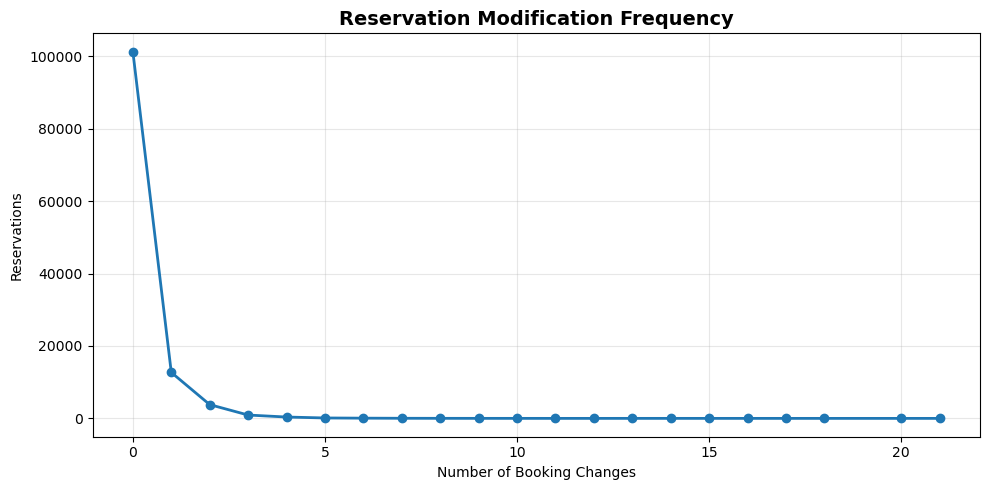

In [11]:
# ==========================================================
# Booking Changes
# ==========================================================

changes = (
    df["booking_changes"]
      .value_counts()
      .sort_index()
)

plt.figure(figsize=(10,5))

plt.plot(
    changes.index,
    changes.values,
    marker="o",
    linewidth=2
)

plt.title(
    "Reservation Modification Frequency",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Booking Changes")
plt.ylabel("Reservations")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observations

- The majority of reservations were completed **without any booking modifications**.
- Reservation changes decrease sharply after the first modification, with only a small number of bookings experiencing multiple changes.
- Extensive booking modifications are relatively rare.

### Business Insight

Most customers finalize their reservations at the time of booking, indicating stable booking behaviour and predictable operational planning. Hotels can therefore focus operational resources on managing a relatively small subset of modified reservations while using booking history to improve forecasting accuracy.

### Section Summary

Booking behaviour analysis shows that customers typically reserve their stays well in advance, favour short-duration visits, rarely modify their reservations, and are predominantly first-time guests. These behavioural patterns provide a strong foundation for occupancy forecasting and suggest opportunities to improve customer retention while supporting the development of data-driven pricing strategies.

## 6. Cancellation Analysis

Reservation cancellations directly affect occupancy planning, pricing decisions, and revenue generation.

This section investigates cancellation behaviour across hotel types, booking windows, customer segments, and deposit policies to identify the major factors contributing to lost revenue.

### Business Question 1

**What proportion of hotel reservations are cancelled?**

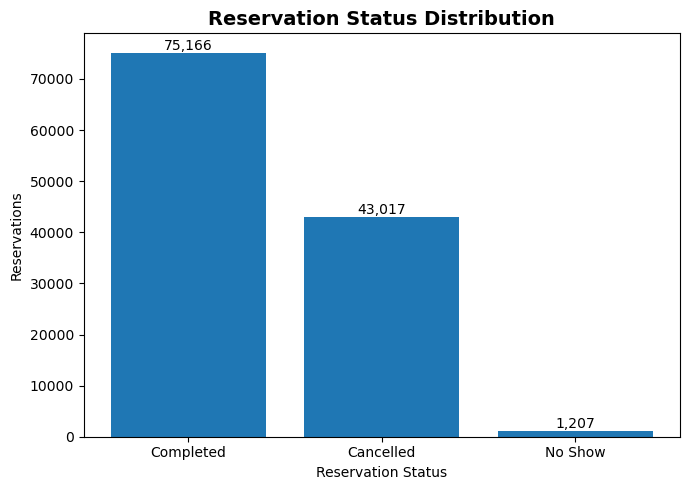

In [12]:
# ==========================================================
# Reservation Status Distribution
# ==========================================================

status = (
    df["booking_status"]
      .value_counts()
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    status.index,
    status.values
)

plt.title(
    "Reservation Status Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Reservation Status")
plt.ylabel("Reservations")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- **75,166 reservations** were successfully completed, representing the majority of bookings.
- **43,017 reservations** were cancelled before arrival, indicating a substantial level of booking loss.
- Only **1,207 reservations** resulted in a no-show, making it the least common reservation outcome.
- Reservation cancellations represent a significant operational and revenue challenge for the hotel.

### Business Insight

Although most reservations are completed successfully, the large volume of cancellations can significantly impact occupancy forecasts and revenue planning. Hotels should incorporate expected cancellation behaviour into demand forecasting models rather than assuming every reservation will convert into an occupied room.

> **Pricing Simulator Link**
>
> Expected cancellations should be incorporated into occupancy forecasts before applying dynamic pricing rules. This prevents hotels from underestimating future room availability.

### Business Question 2

**How does cancellation behaviour vary across booking lead times?**

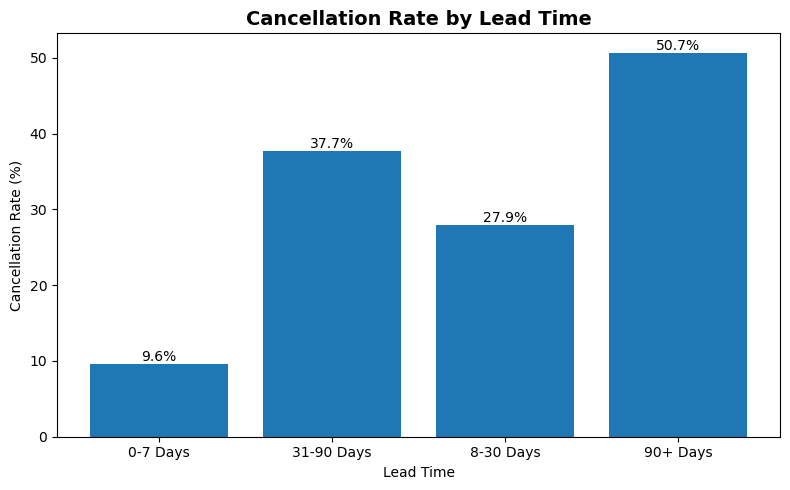

In [13]:
# ==========================================================
# Cancellation Rate by Lead Time Bucket
# ==========================================================

cancel_rate = (
    df.groupby("lead_time_bucket")["is_canceled"]
      .mean()
      .mul(100)
      .round(1)
)

plt.figure(figsize=(8,5))

bars = plt.bar(
    cancel_rate.index.astype(str),
    cancel_rate.values
)

plt.title(
    "Cancellation Rate by Lead Time",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Lead Time")
plt.ylabel("Cancellation Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- Reservations made **more than 90 days in advance** recorded the highest cancellation rate at **50.7%**.
- Bookings made **31–90 days** before arrival also experienced a relatively high cancellation rate (**37.7%**).
- Reservations made within **0–7 days** had the lowest cancellation rate (**9.6%**).
- Cancellation risk increases noticeably as booking lead time increases.

### Business Insight

Customers who book far in advance are significantly more likely to cancel their reservations than last-minute guests. Hotels should therefore treat early bookings as less certain when forecasting occupancy and avoid assuming that all long-term reservations will materialize.

### Business Question 3

**How does deposit policy influence reservation cancellations?**

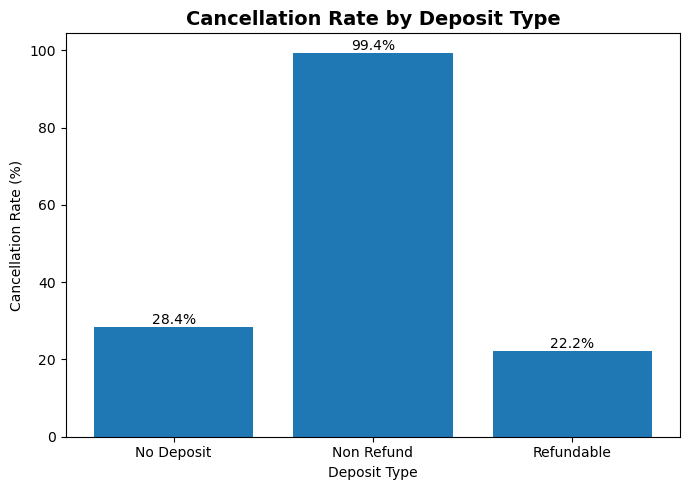

In [14]:
# ==========================================================
# Cancellation Rate by Deposit Type
# ==========================================================

deposit = (
    df.groupby("deposit_type")["is_canceled"]
      .mean()
      .mul(100)
      .round(1)
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    deposit.index,
    deposit.values
)

plt.title(
    "Cancellation Rate by Deposit Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- Reservations with **Non-Refund** deposits experienced the highest cancellation rate (**99.4%**).
- Bookings without a deposit recorded a cancellation rate of **28.4%**.
- Refundable deposits showed the lowest cancellation rate (**22.2%**).
- Cancellation behaviour varies considerably across different deposit policies.

> **Note**
>
> The exceptionally high cancellation rate observed for **Non-Refund** bookings reflects the characteristics of the original dataset and should not be interpreted as evidence that non-refundable policies directly increase cancellations. Further investigation would be required in a real-world business environment.

### Business Insight

Deposit policies are strongly associated with cancellation behaviour and should be considered when evaluating booking risk. Hotels may use deposit information as an additional indicator when estimating future occupancy and revenue.

### Business Question 4

**Which hotel type experiences the highest cancellation rate?**

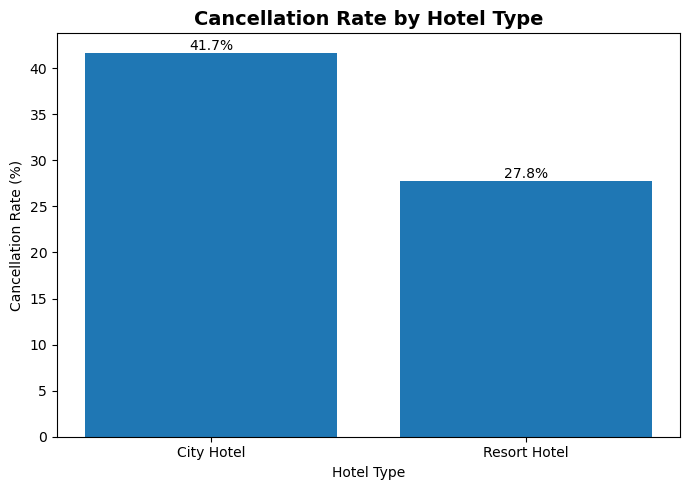

In [15]:
# ==========================================================
# Cancellation Rate by Hotel Type
# ==========================================================

hotel_cancel = (
    df.groupby("hotel")["is_canceled"]
      .mean()
      .mul(100)
      .round(1)
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    hotel_cancel.index,
    hotel_cancel.values
)

plt.title(
    "Cancellation Rate by Hotel Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- **City Hotels** recorded a cancellation rate of **41.7%**, substantially higher than Resort Hotels.
- **Resort Hotels** experienced a lower cancellation rate of **27.8%**.
- Cancellation behaviour differs considerably between the two hotel types.

### Business Insight

City Hotels face a greater risk of reservation cancellations and therefore require more conservative occupancy forecasting and pricing strategies. Resort Hotels exhibit more stable booking behaviour, allowing revenue managers to forecast occupancy with greater confidence.

### Section Summary

Cancellation analysis reveals that reservation risk varies significantly across booking lead times, hotel types, and deposit policies. Early bookings and City Hotels experience substantially higher cancellation rates, highlighting the importance of incorporating expected cancellations into occupancy forecasting. These findings provide a critical foundation for the dynamic pricing engine, enabling more accurate demand estimation and revenue optimization.

## 7. Pricing Analysis

Pricing is one of the most influential factors affecting hotel revenue. Understanding how Average Daily Rate (ADR) varies across hotel types, customer segments, booking behaviour, and seasons provides the foundation for designing an effective dynamic pricing strategy.

This section explores pricing patterns and identifies opportunities for revenue optimization.

### Business Question 1

**How does the Average Daily Rate (ADR) differ between City Hotels and Resort Hotels?**

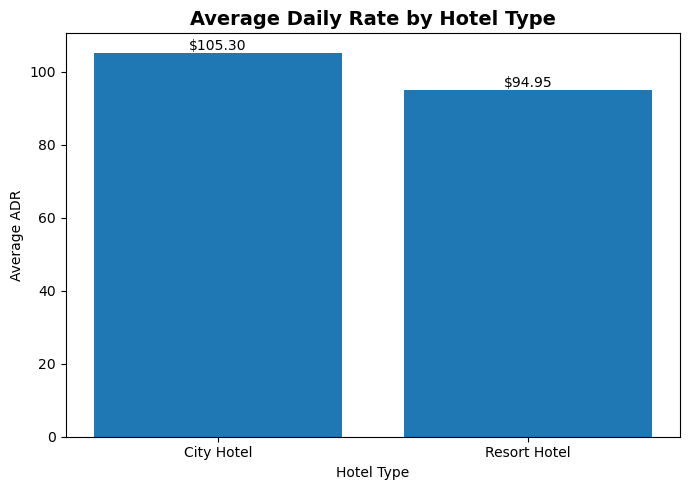

In [16]:
# ==========================================================
# Average ADR by Hotel Type
# ==========================================================

hotel_adr = (
    df.groupby("hotel")["adr"]
      .mean()
      .round(2)
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    hotel_adr.index,
    hotel_adr.values
)

plt.title(
    "Average Daily Rate by Hotel Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Hotel Type")
plt.ylabel("Average ADR")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"${bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- City Hotels recorded an average ADR of **$105.30**, higher than Resort Hotels at **$94.95**.
- On average, guests pay approximately **11% more** for City Hotel reservations.
- The pricing difference indicates that City Hotels command a premium despite also receiving higher booking demand.

### Business Insight

City Hotels demonstrate both stronger demand and higher average room rates, making them the primary revenue-generating property type. Revenue management strategies should therefore prioritize pricing optimization for City Hotels, where even small ADR improvements can produce substantial revenue gains.

### Business Question 2

**How does room price change across booking lead times?**

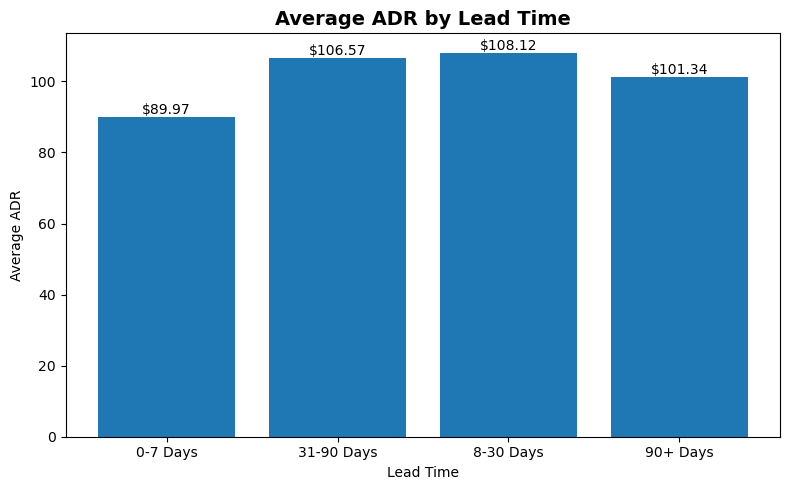

In [17]:
# ==========================================================
# Average ADR by Lead Time
# ==========================================================

lead_adr = (
    df.groupby("lead_time_bucket")["adr"]
      .mean()
      .round(2)
)

plt.figure(figsize=(8,5))

bars = plt.bar(
    lead_adr.index.astype(str),
    lead_adr.values
)

plt.title(
    "Average ADR by Lead Time",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Lead Time")
plt.ylabel("Average ADR")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"${bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- Last-minute bookings (**0–7 days**) have the lowest average ADR at **$89.97**.
- ADR increases substantially for bookings made **31–90 days** (**$106.57**) and **8–30 days** (**$108.12**).
- Reservations made more than **90 days** in advance maintain a relatively high ADR (**$101.34**).
- The lowest prices are associated with last-minute reservations rather than early bookings.

### Business Insight

The observed pricing pattern suggests that hotels reduce room rates as the arrival date approaches, likely to increase occupancy and minimize unsold inventory. This behaviour aligns with revenue management principles, where prices are adjusted according to expected demand and remaining room availability.

### Business Question 3

**Which customer segments generate the highest room rates?**

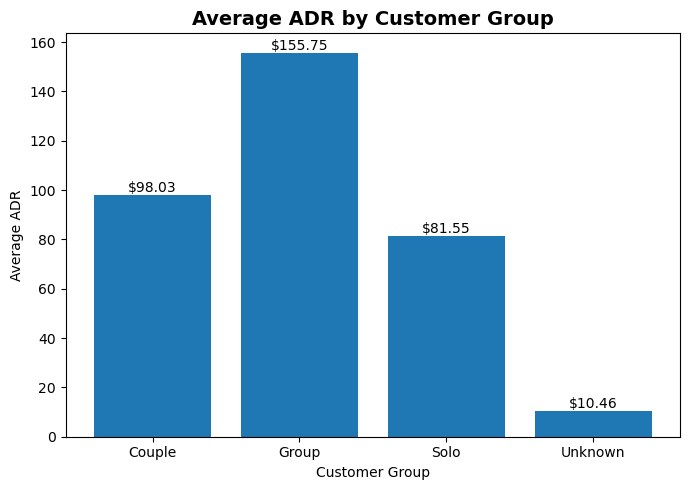

In [18]:
# ==========================================================
# Average ADR by Customer Group
# ==========================================================

family_adr = (
    df.groupby("family_type")["adr"]
      .mean()
      .round(2)
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    family_adr.index,
    family_adr.values
)

plt.title(
    "Average ADR by Customer Group",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Customer Group")
plt.ylabel("Average ADR")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"${bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- **Group bookings** recorded the highest average ADR at **$155.75**.
- **Couples** paid an average ADR of **$98.03**, while **Solo travellers** averaged **$81.55**.
- The **Unknown** category recorded a very low ADR (**$10.46**), representing only a small number of reservations and therefore having limited analytical significance.
- Pricing varies considerably across customer groups, indicating differences in booking behaviour and purchasing patterns.

### Business Insight

Group reservations generate the highest average room rates and represent a valuable revenue segment. Hotels may benefit from developing specialized packages, conference offers, or event-based pricing strategies to attract and retain high-value group bookings while continuing to serve leisure travellers through targeted promotions.

### Business Question 4

**How does Average Daily Rate (ADR) vary throughout the year?**

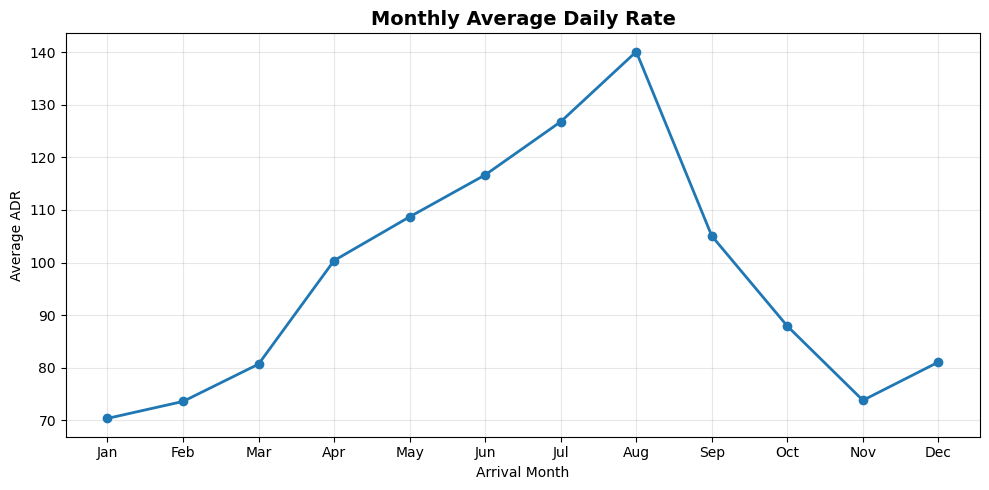

In [19]:
# ==========================================================
# Monthly Average ADR
# ==========================================================

monthly_adr = (
    df.groupby("arrival_month_number")["adr"]
      .mean()
)

months = [
    "Jan","Feb","Mar","Apr","May","Jun",
    "Jul","Aug","Sep","Oct","Nov","Dec"
]

plt.figure(figsize=(10,5))

plt.plot(
    monthly_adr.index,
    monthly_adr.values,
    marker="o",
    linewidth=2
)

plt.xticks(range(1,13), months)

plt.title(
    "Monthly Average Daily Rate",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Arrival Month")
plt.ylabel("Average ADR")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observations

- Average ADR increases steadily from **January through August**, reaching a peak of approximately **$140** in **August**.
- Room prices decline sharply after August, with ADR falling throughout September, October, and November.
- December shows a modest recovery following the seasonal decline.
- The pricing trend closely follows the seasonal demand pattern observed earlier in the analysis.

### Business Insight

Room pricing exhibits strong seasonality, with hotels charging premium rates during peak travel periods and lower rates during off-peak months. This confirms that seasonal demand is a major driver of pricing decisions and should remain a core input to any revenue management strategy.

### Section Summary

Pricing analysis demonstrates that Average Daily Rate varies significantly across hotel types, booking windows, customer segments, and seasons. City Hotels command higher room rates than Resort Hotels, while group bookings generate the highest average revenue per reservation. Seasonal pricing patterns closely align with demand fluctuations, reinforcing the importance of dynamic pricing over static rate strategies. These findings provide direct business evidence for the pricing rules that will be implemented in the revenue management simulator.

## 8. Customer Segmentation Analysis

Customer segments exhibit different booking behaviours, pricing characteristics, and revenue potential. Identifying these differences enables hotels to develop targeted marketing campaigns, improve occupancy, and maximize customer lifetime value.

This section analyzes customer types, market segments, distribution channels, and special requests to understand the characteristics of different customer groups.

### Business Question 1

**Which market segments generate the highest booking demand?**

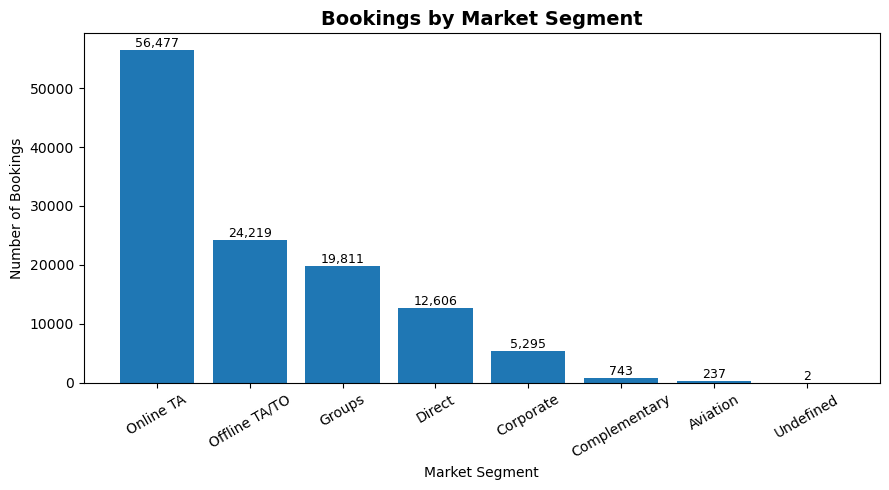

In [20]:
# ==========================================================
# Bookings by Market Segment
# ==========================================================

market = (
    df["market_segment"]
      .value_counts()
)

plt.figure(figsize=(9,5))

bars = plt.bar(
    market.index,
    market.values
)

plt.title(
    "Bookings by Market Segment",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Market Segment")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=30)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

### Observations

- **Online Travel Agencies (Online TA)** generated the highest number of reservations with **56,477 bookings**.
- **Offline TA/TO** contributed **24,219 bookings**, making it the second-largest market segment.
- **Groups** accounted for **19,811 reservations**, while **Direct bookings** totaled **12,606**.
- Corporate, Complementary, Aviation, and Undefined segments collectively represent only a small portion of total demand.

### Business Insight

The hotel relies heavily on Online Travel Agencies for customer acquisition, highlighting the importance of maintaining strong visibility on online booking platforms. At the same time, increasing direct bookings through loyalty programs and targeted marketing could reduce commission costs and improve overall profitability.

### Business Question 2

**Which distribution channels contribute the most reservations?**

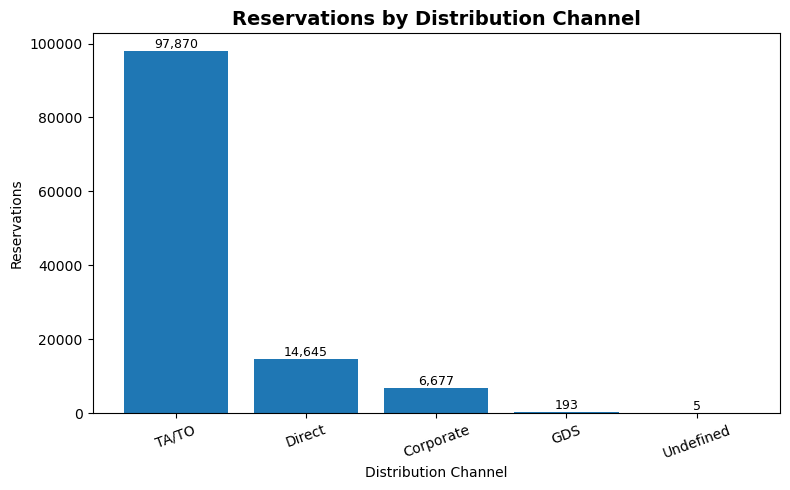

In [21]:
# ==========================================================
# Distribution Channel Analysis
# ==========================================================

channel = (
    df["distribution_channel"]
      .value_counts()
)

plt.figure(figsize=(8,5))

bars = plt.bar(
    channel.index,
    channel.values
)

plt.title(
    "Reservations by Distribution Channel",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Distribution Channel")
plt.ylabel("Reservations")

plt.xticks(rotation=20)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

### Observations

- **TA/TO (Travel Agents/Tour Operators)** is the dominant distribution channel, contributing **97,870 reservations**.
- Direct bookings account for **14,645 reservations**, significantly lower than TA/TO.
- Corporate channels generated **6,677 bookings**, while GDS and Undefined channels contributed only a negligible number of reservations.
- The hotel network depends heavily on intermediary booking channels for customer acquisition.

### Business Insight

The strong dependence on Travel Agents and Tour Operators indicates a successful distribution strategy but also suggests higher commission expenses. Increasing the share of direct reservations would improve profit margins while reducing reliance on intermediary channels.

### Business Question 3

**How many special requests do customers typically make?**

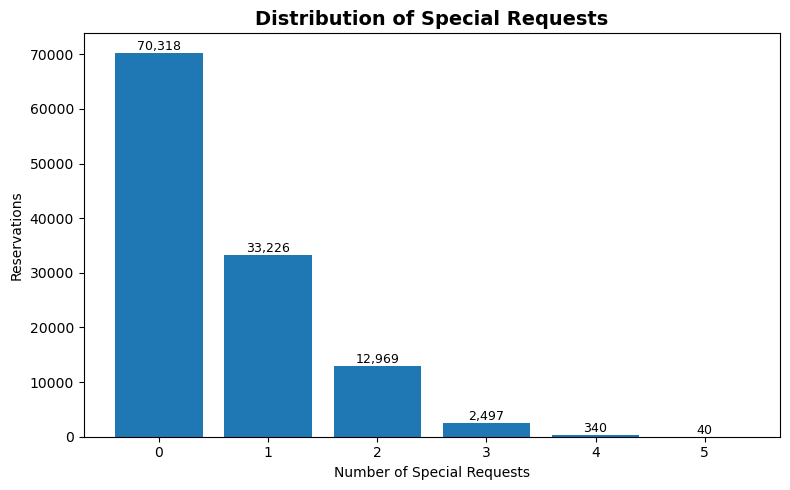

In [22]:
# ==========================================================
# Special Requests Analysis
# ==========================================================

requests = (
    df["total_of_special_requests"]
      .value_counts()
      .sort_index()
)

plt.figure(figsize=(8,5))

bars = plt.bar(
    requests.index.astype(str),
    requests.values
)

plt.title(
    "Distribution of Special Requests",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Special Requests")
plt.ylabel("Reservations")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

### Observations

- **70,318 reservations** were made without any special requests.
- Approximately **33,226 bookings** included one special request, making it the second most common scenario.
- Reservations with two or more special requests decrease progressively.
- Requests involving four or five special requirements are extremely rare.

### Business Insight

Most guests require little or no additional accommodation beyond a standard reservation, simplifying operational planning. However, identifying guests with multiple special requests presents an opportunity to enhance customer satisfaction through personalized service and targeted premium offerings.

### Business Question 4

**Which customer types contribute the most bookings?**

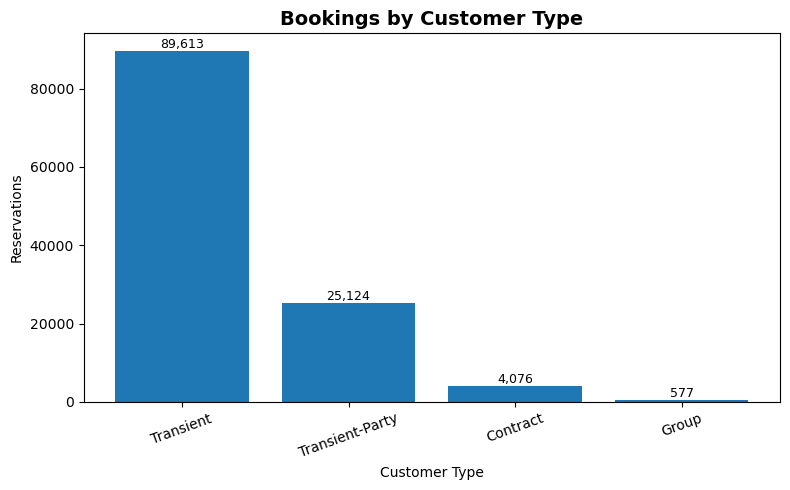

In [23]:
# ==========================================================
# Customer Type Analysis
# ==========================================================

customer = (
    df["customer_type"]
      .value_counts()
)

plt.figure(figsize=(8,5))

bars = plt.bar(
    customer.index,
    customer.values
)

plt.title(
    "Bookings by Customer Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Customer Type")
plt.ylabel("Reservations")

plt.xticks(rotation=20)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

### Observations

- **Transient customers** represent the largest customer type with **89,613 reservations**.
- **Transient-Party** bookings account for **25,124 reservations**, making them the second-largest segment.
- Contract customers contributed **4,076 bookings**, while Group customer types accounted for only **577 reservations**.
- The hotel primarily serves individual leisure and business travellers rather than long-term contractual clients.

### Business Insight

The dominance of transient customers indicates that hotel revenue is primarily driven by short-term individual travellers. Revenue management strategies should therefore focus on dynamic pricing, demand forecasting, and personalized promotions tailored to transient guests while maintaining specialized pricing agreements for contract-based customers.

### Section Summary

Customer segmentation analysis reveals that the hotel's customer base is dominated by Online Travel Agency bookings, Travel Agent distribution channels, and transient travellers. Most guests require minimal special services, simplifying operational planning, while the strong reliance on intermediary channels highlights opportunities to increase direct bookings and improve profitability. These findings provide valuable inputs for customer-specific pricing strategies and future marketing initiatives.

## 9. Seasonal & Temporal Demand Analysis

Hotel demand changes throughout the year due to seasonal travel patterns, holidays, and customer behaviour.

This section explores temporal booking trends across years, quarters, months, and days of the week to identify recurring demand patterns that can support occupancy forecasting and dynamic pricing decisions.

### Business Question 1

**How has booking demand changed over the years?**

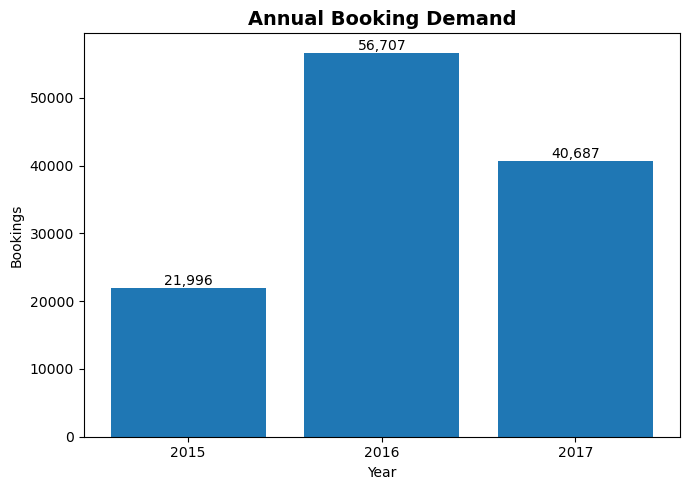

In [24]:
# ==========================================================
# Annual Booking Demand
# ==========================================================

yearly = (
    df["arrival_date_year"]
      .value_counts()
      .sort_index()
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    yearly.index.astype(str),
    yearly.values
)

plt.title(
    "Annual Booking Demand",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Bookings")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- Booking demand increased substantially from **21,996 reservations in 2015** to **56,707 reservations in 2016**.
- Reservations declined to **40,687 in 2017**, but remained significantly higher than 2015.
- The dataset indicates strong year-to-year variation in booking volume.

### Business Insight

Booking demand has not remained constant across the observed years, suggesting that occupancy forecasts and pricing decisions should account for historical demand trends rather than assuming stable booking volumes over time.

### Business Question 2

**Which quarters experience the highest booking demand?**

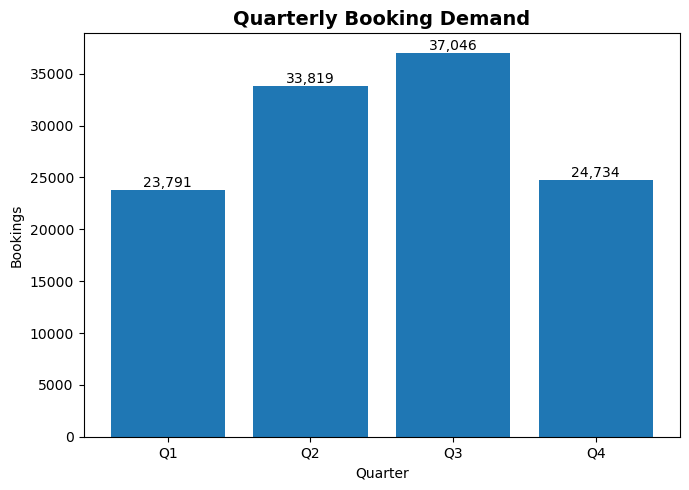

In [25]:
# ==========================================================
# Quarterly Booking Demand
# ==========================================================

quarter = (
    df["arrival_quarter"]
      .value_counts()
      .sort_index()
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    quarter.index,
    quarter.values
)

plt.title(
    "Quarterly Booking Demand",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Quarter")
plt.ylabel("Bookings")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- **Q3** recorded the highest booking demand with **37,046 reservations**.
- **Q2** followed closely with **33,819 bookings**.
- Demand declined considerably during **Q1 (23,791)** and **Q4 (24,734)**.
- The majority of hotel demand is concentrated in the middle of the year.

### Business Insight

The concentration of bookings during Q2 and Q3 confirms a strong seasonal demand cycle. Hotels should prepare for higher occupancy, increased staffing requirements, and premium pricing during these quarters while implementing promotional strategies to stimulate demand in Q1 and Q4.

### Business Question 3

**Which days of the week experience the highest arrivals?**

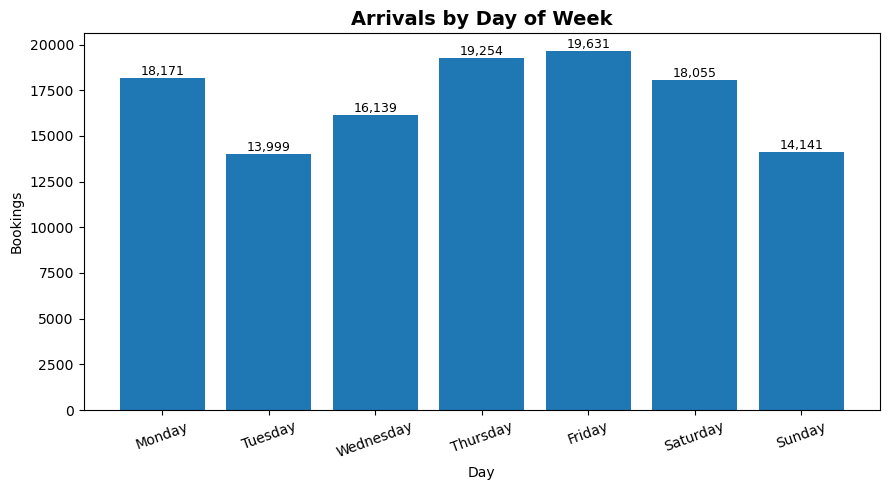

In [26]:
# ==========================================================
# Arrivals by Day of Week
# ==========================================================

days = (
    df["arrival_day_name"]
      .value_counts()
      .reindex([
          "Monday",
          "Tuesday",
          "Wednesday",
          "Thursday",
          "Friday",
          "Saturday",
          "Sunday"
      ])
)

plt.figure(figsize=(9,5))

bars = plt.bar(
    days.index,
    days.values
)

plt.title(
    "Arrivals by Day of Week",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Day")
plt.ylabel("Bookings")

plt.xticks(rotation=20)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

### Observations

- **Friday (19,631)** and **Thursday (19,254)** recorded the highest number of guest arrivals.
- **Monday (18,171)** and **Saturday (18,055)** also experienced relatively strong booking activity.
- **Tuesday (13,999)** and **Sunday (14,141)** showed the lowest arrival volumes.
- Guest arrivals are distributed throughout the week but peak toward the end of the business week.

### Business Insight

The higher arrival volumes on Thursdays and Fridays suggest that many guests begin their stays just before the weekend. Hotels can use this information to optimize staffing schedules, check-in operations, and promotional campaigns targeting weekend travel.

### Business Question 4

**Do guests prefer weekday stays or weekend stays?**

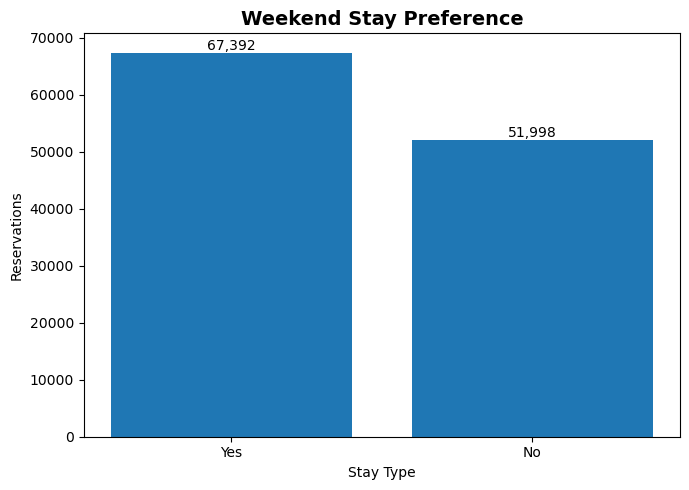

In [27]:
# ==========================================================
# Weekend Stay Preference
# ==========================================================

weekend = (
    df["weekend_stay"]
      .value_counts()
)

plt.figure(figsize=(7,5))

bars = plt.bar(
    weekend.index,
    weekend.values
)

plt.title(
    "Weekend Stay Preference",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Stay Type")
plt.ylabel("Reservations")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observations

- **67,392 reservations** included a weekend stay.
- **51,998 reservations** did not include a weekend stay.
- A majority of guests incorporate at least one weekend night into their visit.

### Business Insight

Weekend stays represent a significant portion of hotel demand, highlighting weekends as an important revenue opportunity. Hotels can capitalize on this preference through weekend packages, promotional offers, and premium pricing during periods of strong occupancy.

### Section Summary

Temporal analysis confirms that hotel demand follows clear seasonal and weekly patterns. Booking activity peaks during Q2 and Q3, with the highest guest arrivals occurring toward the end of the week. A majority of reservations also include weekend stays, reinforcing the importance of incorporating seasonal and temporal demand patterns into occupancy forecasting and dynamic pricing decisions.

# 10. Executive Business Recommendations

Based on the exploratory analysis, the following recommendations are proposed to improve hotel occupancy, revenue generation, and pricing effectiveness.

### 1. Prioritize Dynamic Pricing for City Hotels
City Hotels generate both the highest booking volume and the highest Average Daily Rate (ADR). Revenue optimization efforts should therefore prioritize City Hotels to maximize financial impact.

### 2. Implement Seasonal Pricing Strategies
Demand and ADR peak during Q2 and Q3, particularly in July and August. Hotels should increase room rates during these periods while using targeted promotions during lower-demand seasons.

### 3. Incorporate Expected Cancellations into Occupancy Forecasts
Reservations made well in advance exhibit significantly higher cancellation rates. Forecasting models should estimate expected occupied rooms rather than assuming every reservation will result in a completed stay.

### 4. Increase Direct Bookings
The hotel relies heavily on Online Travel Agencies and Travel Agent distribution channels. Expanding loyalty programs and direct-booking incentives can reduce commission costs and improve profitability.

### 5. Develop Customer-Specific Pricing Strategies
Different customer segments exhibit distinct booking and pricing behaviours. Pricing decisions should account for customer type, booking channel, and market segment rather than applying a uniform pricing policy.

### 6. Build an Occupancy-Driven Pricing Engine
Instead of maintaining static room rates, hotels should dynamically adjust ADR based on occupancy forecasts, seasonal demand, lead time, and expected cancellation behaviour to maximize revenue.

# Notebook Summary

### Key Outcomes

- Identified the primary drivers of hotel booking demand.
- Analyzed customer booking behaviour and cancellation patterns.
- Explored pricing variation across hotel types, customer segments, booking windows, and seasons.
- Investigated customer segmentation and temporal demand trends.
- Derived business recommendations that will serve as the foundation for the SQL analytics and dynamic pricing engine.

### Next Steps

The next notebook will focus on SQL Business Analytics, where the insights discovered in this notebook will be translated into SQL queries, KPIs, and executive metrics to support hotel revenue management decisions.